# Algoritmo de Lee

Encuentra el camino más corto en un laberinto (cuadrícula con obstáculos) mediante BFS: expande una "onda" desde el origen anotando la distancia de cada celda, y reconstruye el camino desde el destino siguiendo distancias decrecientes. Se usa, por ejemplo, para enrutar pistas en circuitos impresos.

## 1. Distancia mínima en un laberinto

Calcular el número mínimo de pasos de `S` a `E` moviéndose en horizontal o vertical sin atravesar muros `#`, o −1 si no hay camino.

In [1]:
from collections import deque

laberinto = [
    "S.#.....",
    ".##.###.",
    "....#...",
    "#.#.#.#.",
    "..#...#E",
]

def busca(lab, simbolo):
    return next((f, c) for f, fila in enumerate(lab) for c, v in enumerate(fila) if v == simbolo)

def lee(lab):
    origen, destino = busca(lab, "S"), busca(lab, "E")
    dist, cola = {origen: 0}, deque([origen])
    while cola:
        f, c = cola.popleft()
        for nf, nc in ((f + 1, c), (f - 1, c), (f, c + 1), (f, c - 1)):
            if 0 <= nf < len(lab) and 0 <= nc < len(lab[0]) and lab[nf][nc] != "#" and (nf, nc) not in dist:
                dist[nf, nc] = dist[f, c] + 1
                cola.append((nf, nc))
    return dist, origen, destino

dist, origen, destino = lee(laberinto)
print(dist.get(destino, -1))

15


## 2. Reconstruir y dibujar el camino

Desde el destino, ir a cualquier vecino con distancia una unidad menor hasta llegar al origen, y dibujar el camino con `*`.

In [2]:
def camino(dist, origen, destino):
    if destino not in dist:
        return None
    actual, ruta = destino, [destino]
    while actual != origen:
        f, c = actual
        actual = next(v for v in ((f + 1, c), (f - 1, c), (f, c + 1), (f, c - 1)) if dist.get(v) == dist[actual] - 1)
        ruta.append(actual)
    return ruta[::-1]

ruta = camino(dist, origen, destino)
dibujo = [list(fila) for fila in laberinto]
for f, c in ruta[1:-1]:
    dibujo[f][c] = "*"
print("\n".join("".join(fila) for fila in dibujo))

S.#*****
*##*###*
****#..*
#.#.#.#*
..#...#E


## 3. Varias salidas

En un edificio con varias salidas `E`, calcular a cuántos pasos está cada una de `S` con un solo BFS desde `S`, y reconstruir y dibujar el camino a la más cercana. Hacerlo también al revés, con un BFS que parte de todas las salidas a la vez (multiorigen): da, para cada celda, la distancia a su salida más cercana.

In [3]:
def bfs(lab, origenes):
    dist, cola = {o: 0 for o in origenes}, deque(origenes)
    while cola:
        f, c = cola.popleft()
        for nf, nc in ((f + 1, c), (f - 1, c), (f, c + 1), (f, c - 1)):
            if 0 <= nf < len(lab) and 0 <= nc < len(lab[0]) and lab[nf][nc] != "#" and (nf, nc) not in dist:
                dist[nf, nc] = dist[f, c] + 1
                cola.append((nf, nc))
    return dist

def busca_todos(lab, simbolo):
    return [(f, c) for f, fila in enumerate(lab) for c, v in enumerate(fila) if v == simbolo]

def dibuja(lab, ruta):
    dibujo = [list(fila) for fila in lab]
    for f, c in ruta[1:-1]:
        dibujo[f][c] = "*"
    print("\n".join("".join(fila) for fila in dibujo))

edificio = [
    "E....#......E",
    ".###.#.####..",
    "...#...#.....",
    "##.#####.###.",
    "...#..S..#...",
    ".#...#.#.#.#.",
    ".#####.###.#.",
    "......E......",
]
inicio, salidas = busca(edificio, "S"), busca_todos(edificio, "E")
dist = bfs(edificio, [inicio])
for salida in salidas:
    print("Salida", salida, "a", dist[salida], "pasos")
cercana = min(salidas, key=dist.get)
dibuja(edificio, camino(dist, inicio, cercana))

hasta_salida = bfs(edificio, salidas)
assert hasta_salida[inicio] == dist[cercana]
print()
for f, fila in enumerate(edificio):
    print(" ".join(" #" if v == "#" else f"{hasta_salida[f, c]:2}" for c, v in enumerate(fila)))

Salida (0, 0) a 12 pasos
Salida (0, 12) a 10 pasos
Salida (7, 6) a 3 pasos
E....#......E
.###.#.####..
...#...#.....
##.#####.###.
...#..S..#...
.#...#*#.#.#.
.#####*###.#.
......E......

 0  1  2  3  4  #  6  5  4  3  2  1  0
 1  #  #  #  5  #  7  #  #  #  #  2  1
 2  3  4  #  6  7  8  #  6  5  4  3  2
 #  #  5  #  #  #  #  #  6  #  #  #  3
 8  7  6  #  5  4  3  4  5  #  6  5  4
 8  #  7  7  6  #  2  #  6  #  6  #  5
 7  #  #  #  #  #  1  #  #  #  5  #  6
 6  5  4  3  2  1  0  1  2  3  4  5  6


## 4. Onda de expansión y comprobación con fuerza bruta

Comprobar la distancia de Lee en rejillas pequeñas aleatorias contra una búsqueda exhaustiva que prueba todos los caminos simples. Después, en una rejilla grande con obstáculos aleatorios, dibujar con `matplotlib` la onda (la distancia de cada celda al origen) y el camino hasta la celda alcanzable más lejana.

Celdas alcanzadas: 927  la más lejana: (28, 37) a 75 pasos


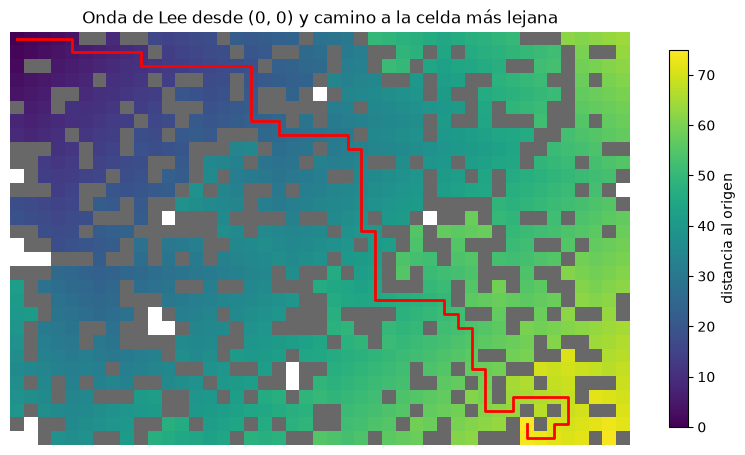

In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt

def fuerza_bruta(lab, origen, destino):
    mejor = float("inf")

    def explora(celda, visitadas):
        nonlocal mejor
        if celda == destino:
            mejor = min(mejor, len(visitadas) - 1)
            return
        f, c = celda
        for v in ((f + 1, c), (f - 1, c), (f, c + 1), (f, c - 1)):
            if 0 <= v[0] < len(lab) and 0 <= v[1] < len(lab[0]) and lab[v[0]][v[1]] != "#" and v not in visitadas:
                visitadas.add(v)
                explora(v, visitadas)
                visitadas.remove(v)

    explora(origen, {origen})
    return mejor if mejor < float("inf") else -1

def rejilla_aleatoria(filas, columnas, densidad):
    return ["".join("#" if random.random() < densidad else "." for _ in range(columnas)) for _ in range(filas)]

random.seed(8)
for _ in range(300):
    lab = rejilla_aleatoria(4, 5, 0.25)
    libres = [(f, c) for f in range(4) for c in range(5) if lab[f][c] == "."]
    if len(libres) < 2:
        continue
    o, d = random.sample(libres, 2)
    assert bfs(lab, [o]).get(d, -1) == fuerza_bruta(lab, o, d)

random.seed(3)
grande = rejilla_aleatoria(30, 45, 0.3)
origen = (0, 0)
grande[0] = "." + grande[0][1:]
onda = bfs(grande, [origen])
lejana = max(onda, key=onda.get)
ruta = camino(onda, origen, lejana)
print("Celdas alcanzadas:", len(onda), " la más lejana:", lejana, "a", onda[lejana], "pasos")

matriz = np.full((30, 45), np.nan)
for (f, c), d in onda.items():
    matriz[f, c] = d
fig, eje = plt.subplots(figsize=(10, 7))
eje.imshow([[x == "#" for x in fila] for fila in grande], cmap="Greys", vmax=1.5)
imagen = eje.imshow(matriz, cmap="viridis")
eje.plot([c for _, c in ruta], [f for f, _ in ruta], color="red", linewidth=2)
fig.colorbar(imagen, ax=eje, shrink=0.7, label="distancia al origen")
eje.set_title("Onda de Lee desde (0, 0) y camino a la celda más lejana")
eje.axis("off")
plt.show()